# CTI Threat Analysis — Document Extraction, Classification & Emerging-Threat Detection

End-to-end pipeline:

1. **Document extraction** — pull plain text from PDF / DOCX / TXT / HTML / MD reports
2. **Classification** — TF-IDF + (Logistic Regression | Naive Bayes | Linear SVM)
3. **Temporal topic modeling** — NMF over monthly report text
4. **Emerging-threat detection** — flag topics whose month-over-month share spikes


## 1. Imports

In [26]:
import os
import re
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.decomposition import NMF
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    ConfusionMatrixDisplay
)

import joblib

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# Make the scripts/ folder importable so we can pull in document_extractor
PROJECT_ROOT = Path(r"D:\Sachin Chakrawarti\Learn\done\thesis\ctc_ectd")
SCRIPTS_DIR = PROJECT_ROOT / "scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

print("Libraries imported successfully.")
print("Project root:", PROJECT_ROOT)

Libraries imported successfully.
Project root: D:\Sachin Chakrawarti\Learn\done\thesis\ctc_ectd


## 2. Document extraction (PDF / DOCX / TXT / HTML / MD)

This section uses `scripts/document_extractor.py` to convert raw CTI documents 
into clean plain text that the classifiers and topic model can consume.

Supported formats: `.pdf`, `.docx`, `.txt`, `.md`, `.log`, `.html`, `.htm`, `.csv`.

Install the extractors once:
```
pip install pypdf python-docx beautifulsoup4 lxml
```

In [27]:
from document_extractor import (
    extract_text,
    clean_extracted_text,
    extract_and_clean,
    EXTRACTORS,
)

print("Supported extensions:", ", ".join(sorted(EXTRACTORS)))

# Folder where the user drops raw CTI documents to analyse
UPLOAD_DIR = PROJECT_ROOT / "uploads"
UPLOAD_DIR.mkdir(exist_ok=True)
print("Upload folder:", UPLOAD_DIR)

Supported extensions: .csv, .doc, .docx, .htm, .html, .log, .md, .pdf, .txt
Upload folder: D:\Sachin Chakrawarti\Learn\done\thesis\ctc_ectd\uploads


In [28]:
def load_documents(folder: Path) -> pd.DataFrame:
    """Walk `folder` and extract text from every supported document."""
    rows = []
    for path in sorted(folder.rglob("*")):
        if not path.is_file():
            continue
        if path.suffix.lower() not in EXTRACTORS:
            continue
        try:
            raw = extract_text(path)
            cleaned = clean_extracted_text(raw)
            rows.append({
                "file_name": path.name,
                "file_path": str(path),
                "extension": path.suffix.lower(),
                "char_count": len(cleaned),
                "word_count": len(cleaned.split()),
                "raw_text": raw,
                "text": cleaned,
            })
        except Exception as exc:
            print(f"[WARN] {path.name}: {exc}")
            rows.append({
                "file_name": path.name,
                "file_path": str(path),
                "extension": path.suffix.lower(),
                "char_count": 0,
                "word_count": 0,
                "raw_text": "",
                "text": "",
            })
    return pd.DataFrame(rows)


# ---------- Demo: single-document extraction ----------
# Uncomment to test one file at a time.
# sample_file = UPLOAD_DIR / "example_report.pdf"
# sample_text = extract_and_clean(sample_file)
# print(sample_text[:1500])

In [29]:
# Load whatever documents are currently in the uploads/ folder
uploaded_df = load_documents(UPLOAD_DIR)

if uploaded_df.empty:
    print("No documents found in", UPLOAD_DIR)
    print("Drop CTI reports (PDF/DOCX/TXT/HTML) into that folder and re-run.")
else:
    print(f"Extracted text from {len(uploaded_df)} document(s).")
    display(uploaded_df[[
        "file_name", "extension", "char_count", "word_count"
    ]].sort_values("char_count", ascending=False))

    # Preview the longest document
    longest = uploaded_df.sort_values("char_count", ascending=False).iloc[0]
    print("\nPreview:", longest["file_name"])
    print(longest["text"][:1200], "...")

No documents found in D:\Sachin Chakrawarti\Learn\done\thesis\ctc_ectd\uploads
Drop CTI reports (PDF/DOCX/TXT/HTML) into that folder and re-run.


## 3. Load labelled training data

The classifier is trained on the synthetic CTI corpus that already carries a 
`category` label. Extracted documents (Section 2) are then scored against it.

In [30]:
DATA_PATH = PROJECT_ROOT / "dataset" / "synthetic_cti_reports.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Place synthetic_cti_reports.csv inside the dataset/ folder."
    )

df = pd.read_csv(DATA_PATH)
print("Training corpus shape:", df.shape)
display(df.head())
print("\nColumns:", df.columns.tolist())

Training corpus shape: (10000, 17)


,id,title,text,category,date,source,url,severity,threat_actor,malware,attack_vector,target_sector,country,cve_id,mitre_technique,mitre_technique_name,indicators
0,3568,DDoS activity targeting Retail organizations,A recent threat campaign involved ddos activit...,DDoS,2021-01-01,CTI-Source-6,https://cti-reports.example.org/report/3568,High,BlackOrchid,SilverWorm,Drive-by Download,Retail,Japan,CVE-2022-39414,T1059,Command and Scripting Interpreter,IP=111.96.63.206; DOMAIN=wall-west.net; SHA256...
1,5617,Web Attack activity targeting Financial Servic...,A medium web attack campaign targeted organiza...,Web Attack,2021-01-01,CTI-Source-9,https://cti-reports.example.org/report/5617,Medium,DarkHydra,DarkLoader,Brute Force,Financial Services,United States,CVE-2024-29220,T1053,Scheduled Task/Job,IP=150.80.211.45; DOMAIN=austin-moreno.net; SH...
2,2016,Credential Theft activity targeting Retail org...,A high credential theft campaign targeted orga...,Credential Theft,2021-01-01,CTI-Source-11,https://cti-reports.example.org/report/2016,High,StormByte,SilverWorm,Exposed Service,Retail,Australia,CVE-2026-54394,T1566.001,Spearphishing Attachment,IP=143.178.240.66; DOMAIN=briggs.org; SHA256=f...
3,4000,Credential Theft activity targeting Government...,A recent threat campaign involved credential t...,Credential Theft,2021-01-01,CTI-Source-2,https://cti-reports.example.org/report/4000,Critical,NightWolf,RedLineX,Exposed Service,Government,United States,CVE-2026-60798,T1059,Command and Scripting Interpreter,IP=46.62.120.64; DOMAIN=williams.com; SHA256=3...
4,1066,Phishing activity targeting Banking organizations,A high phishing campaign targeted organization...,Phishing,2021-01-01,CTI-Source-1,https://cti-reports.example.org/report/1066,High,APT-Alpha,ShadowRAT,Brute Force,Banking,India,CVE-2023-68334,T1083,File and Directory Discovery,IP=33.169.134.207; DOMAIN=holmes-matthews.org;...



Columns: ['id', 'title', 'text', 'category', 'date', 'source', 'url', 'severity', 'threat_actor', 'malware', 'attack_vector', 'target_sector', 'country', 'cve_id', 'mitre_technique', 'mitre_technique_name', 'indicators']


## 4. Detect key columns

In [31]:
def find_column(columns, candidates):
    lookup = {str(col).strip().lower(): col for col in columns}
    for cand in candidates:
        if cand in lookup:
            return lookup[cand]
    return None


TEXT_COL  = find_column(df.columns,
    ["text", "report_text", "description", "content",
     "narrative", "report", "body"])
TITLE_COL = find_column(df.columns,
    ["title", "report_title", "name"])
LABEL_COL = find_column(df.columns,
    ["attack_type", "label", "category", "threat_type",
     "class", "target"])
DATE_COL  = find_column(df.columns,
    ["date", "published_date", "report_date",
     "created_at", "timestamp"])

print("TEXT_COL:",  TEXT_COL)
print("TITLE_COL:", TITLE_COL)
print("LABEL_COL:", LABEL_COL)
print("DATE_COL:",  DATE_COL)

if TEXT_COL is None:
    raise ValueError("Text column not detected.")
if LABEL_COL is None:
    raise ValueError("Label column not detected.")

TEXT_COL: text
TITLE_COL: title
LABEL_COL: category
DATE_COL: date


## 5. Clean the training corpus

In [32]:
df = df.copy()
df[TEXT_COL]  = df[TEXT_COL].fillna("").astype(str).str.strip()
df[LABEL_COL] = df[LABEL_COL].fillna("").astype(str).str.strip()

df = df[(df[TEXT_COL] != "") & (df[LABEL_COL] != "")].copy()
df = df.drop_duplicates(subset=[TEXT_COL]).reset_index(drop=True)

if TITLE_COL is not None:
    df[TITLE_COL] = df[TITLE_COL].fillna("").astype(str).str.strip()
    df["model_text"] = (df[TITLE_COL] + " " + df[TEXT_COL]).str.strip()
else:
    df["model_text"] = df[TEXT_COL]

print("Cleaned shape:", df.shape)
display(df[LABEL_COL].value_counts().to_frame("report_count"))

Cleaned shape: (10000, 18)


,report_count
category,
Ransomware,1041
Web Attack,1040
DDoS,1027
Vulnerability,1020
Credential Theft,993
Data Breach,990
Botnet,987
Malware,986
Phishing,983


## 6. Exploratory Data Analysis

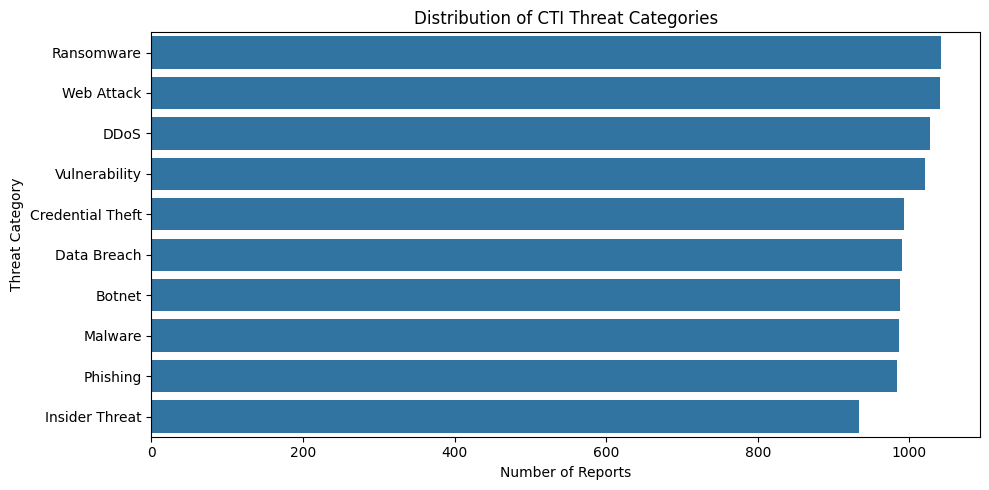

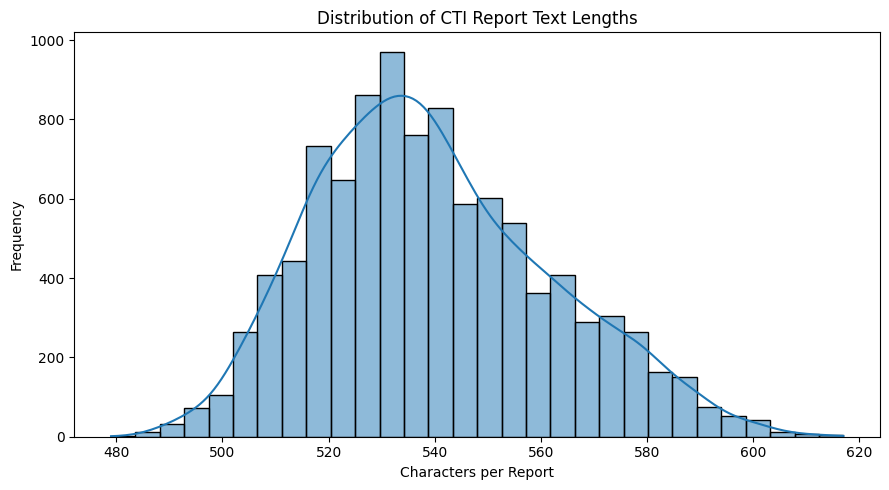

Missing values:


,missing_values
id,0
title,0
text,0
category,0
date,0
source,0
url,0
severity,0
threat_actor,0
malware,0


Classes: 10
Reports: 10000


In [33]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y=LABEL_COL,
              order=df[LABEL_COL].value_counts().index)
plt.title("Distribution of CTI Threat Categories")
plt.xlabel("Number of Reports")
plt.ylabel("Threat Category")
plt.tight_layout()
plt.show()

df["text_length"] = df["model_text"].str.len()
plt.figure(figsize=(9, 5))
sns.histplot(df["text_length"], bins=30, kde=True)
plt.title("Distribution of CTI Report Text Lengths")
plt.xlabel("Characters per Report")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print("Missing values:")
display(df.isnull().sum().to_frame("missing_values"))
print("Classes:", df[LABEL_COL].nunique())
print("Reports:", len(df))

## 7. Enhanced Exploratory Data Analysis

Every cell below is defensive — it skips gracefully when a column is missing.

### 7.1 Detailed label distribution

,Count,Percentage
category,,
Ransomware,1041,10.41
Web Attack,1040,10.40
DDoS,1027,10.27
Vulnerability,1020,10.20
Credential Theft,993,9.93
Data Breach,990,9.90
Botnet,987,9.87
Malware,986,9.86
Phishing,983,9.83


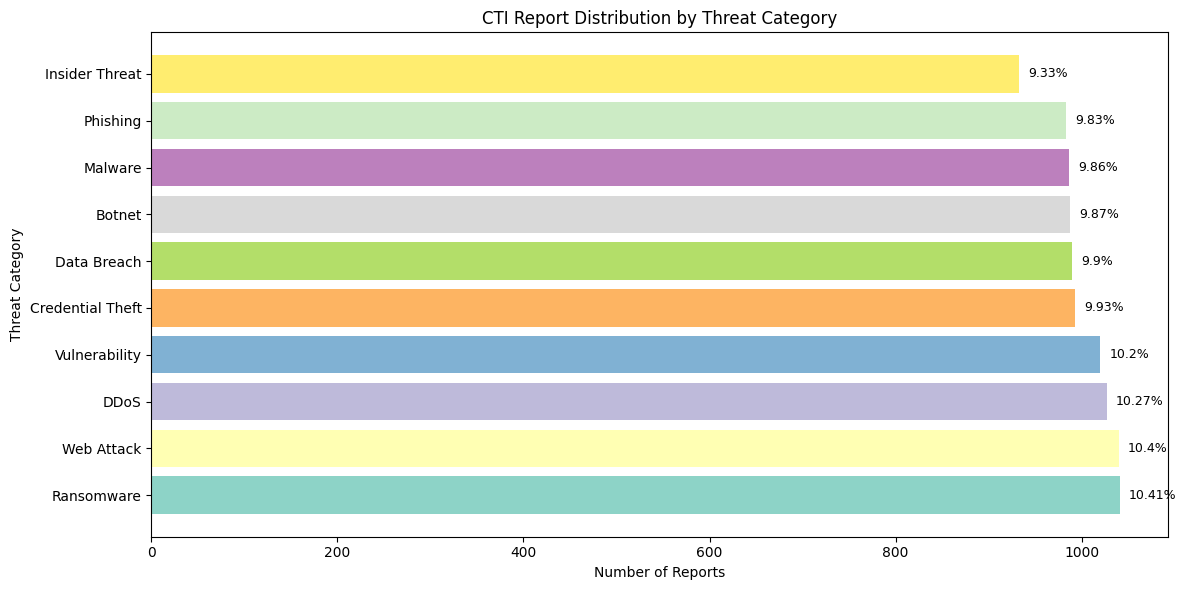

In [34]:
label_counts = df[LABEL_COL].value_counts()
label_pct = (label_counts / len(df) * 100).round(2)
display(pd.DataFrame({"Count": label_counts, "Percentage": label_pct}))

fig, ax = plt.subplots(figsize=(12, 6))
colors = plt.cm.Set3(np.linspace(0, 1, len(label_counts)))
bars = ax.barh(label_counts.index, label_counts.values, color=colors)
ax.set_xlabel("Number of Reports")
ax.set_ylabel("Threat Category")
ax.set_title("CTI Report Distribution by Threat Category")
for bar, pct in zip(bars, label_pct.values):
    ax.text(bar.get_width() + 10,
            bar.get_y() + bar.get_height()/2,
            f'{pct}%', ha='left', va='center', fontsize=9)
plt.tight_layout(); plt.show()

### 7.2 Severity distribution

,Count
severity,
Low,2603
Medium,2499
Critical,2476
High,2422


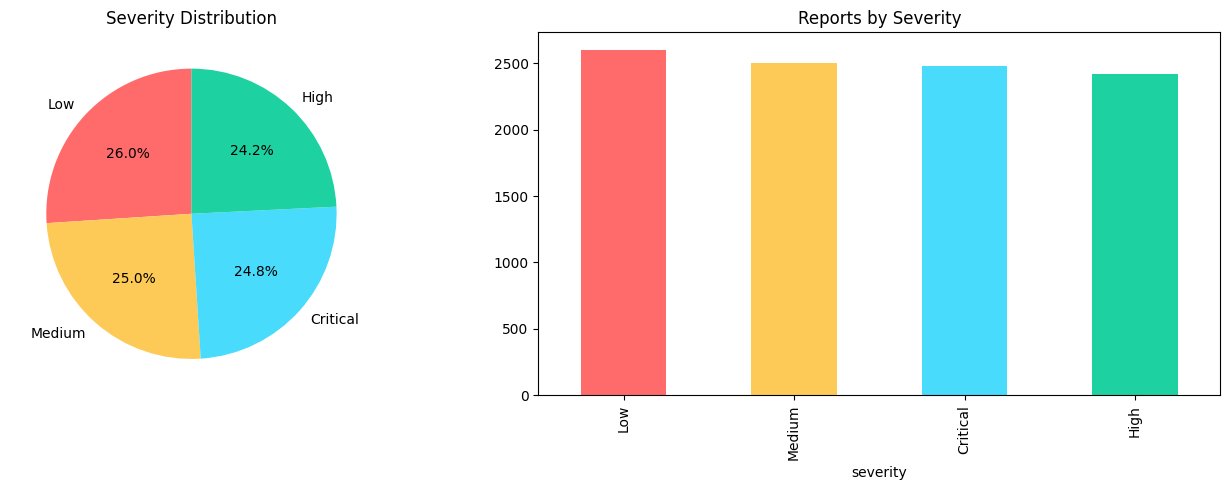

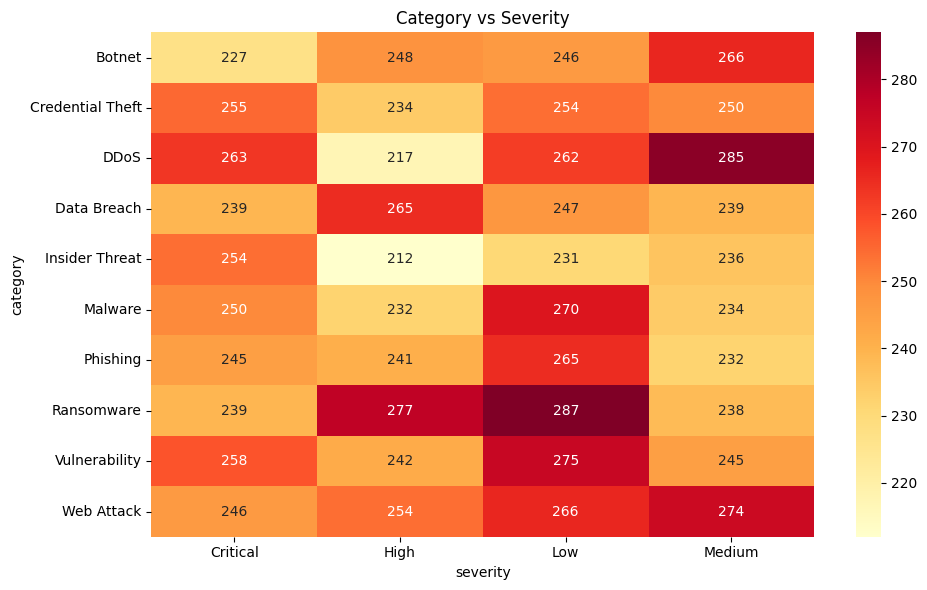

In [35]:
SEVERITY_COL = find_column(df.columns,
    ["severity", "threat_level", "risk_level", "priority"])
if SEVERITY_COL is not None:
    s_counts = df[SEVERITY_COL].value_counts()
    display(s_counts.to_frame("Count"))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    colors = ["#ff6b6b", "#feca57", "#48dbfb", "#1dd1a1"]
    axes[0].pie(s_counts.values, labels=s_counts.index,
                autopct='%1.1f%%',
                colors=colors[:len(s_counts)], startangle=90)
    axes[0].set_title("Severity Distribution")
    s_counts.plot(kind='bar', ax=axes[1],
                  color=colors[:len(s_counts)])
    axes[1].set_title("Reports by Severity")
    plt.tight_layout(); plt.show()
    ct = pd.crosstab(df[LABEL_COL], df[SEVERITY_COL])
    plt.figure(figsize=(10, 6))
    sns.heatmap(ct, annot=True, fmt='d', cmap='YlOrRd')
    plt.title("Category vs Severity")
    plt.tight_layout(); plt.show()
else:
    print("No severity column.")

### 7.3 Target sector

,Count
target_sector,
Retail,1055
Financial Services,1038
Energy,1034
Healthcare,999
Technology,995
Government,985
Manufacturing,982
Telecommunications,976
Banking,972


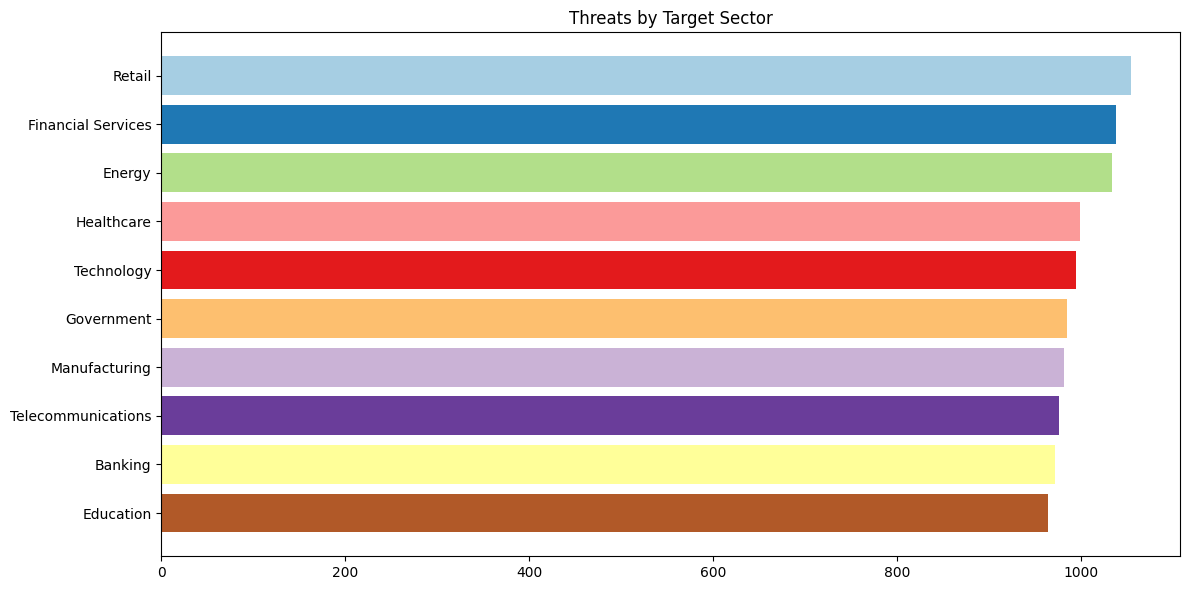

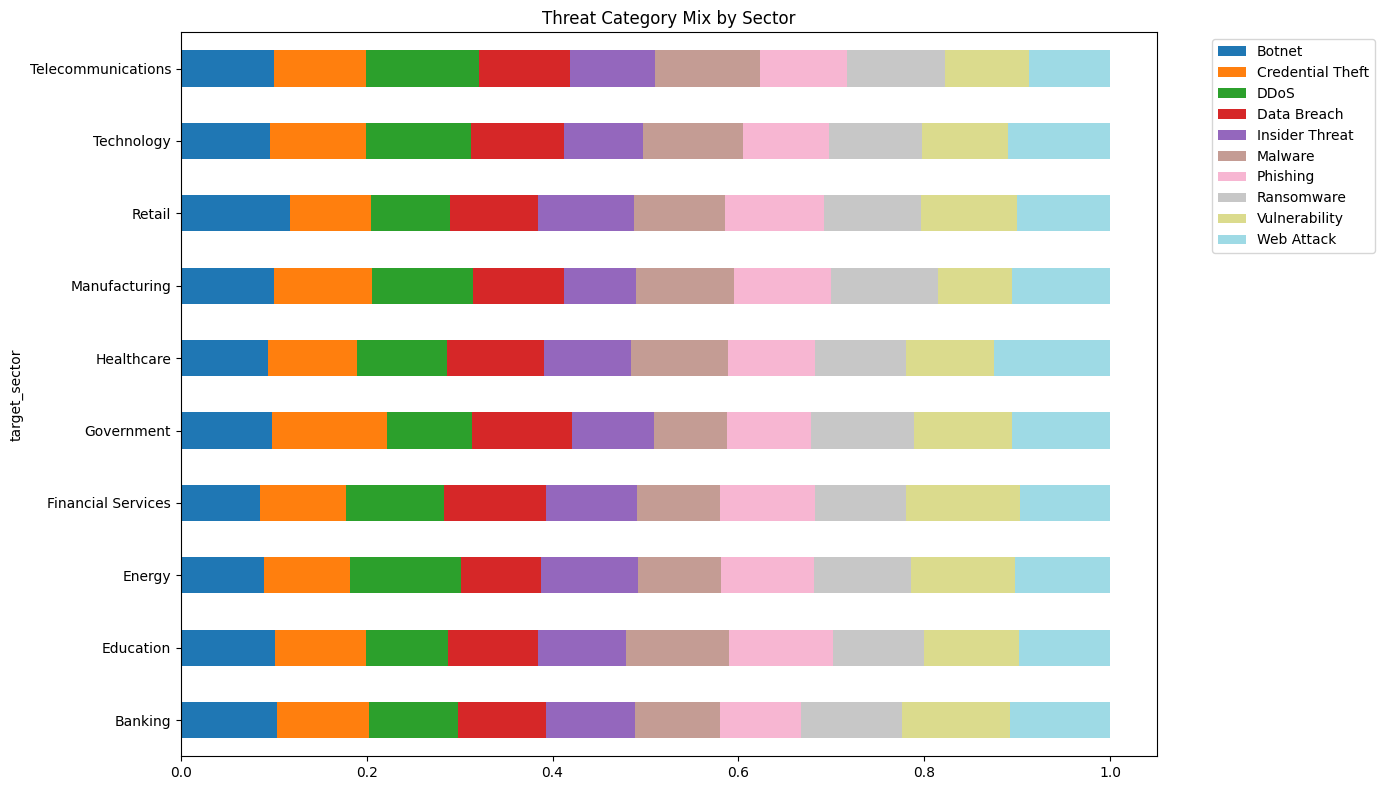

In [36]:
SECTOR_COL = find_column(df.columns,
    ["target_sector", "sector", "industry", "target_industry"])
if SECTOR_COL is not None:
    sec_counts = df[SECTOR_COL].value_counts()
    display(sec_counts.to_frame("Count"))
    fig, ax = plt.subplots(figsize=(12, 6))
    colors = plt.cm.Paired(np.linspace(0, 1, len(sec_counts)))
    bars = ax.barh(sec_counts.index, sec_counts.values, color=colors)
    ax.set_title("Threats by Target Sector")
    ax.invert_yaxis()
    plt.tight_layout(); plt.show()
    sec_cat = pd.crosstab(df[SECTOR_COL], df[LABEL_COL],
                          normalize='index')
    sec_cat.plot(kind='barh', stacked=True, figsize=(14, 8),
                 colormap='tab20')
    plt.title("Threat Category Mix by Sector")
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout(); plt.show()
else:
    print("No target sector column.")

### 7.4 Temporal distribution

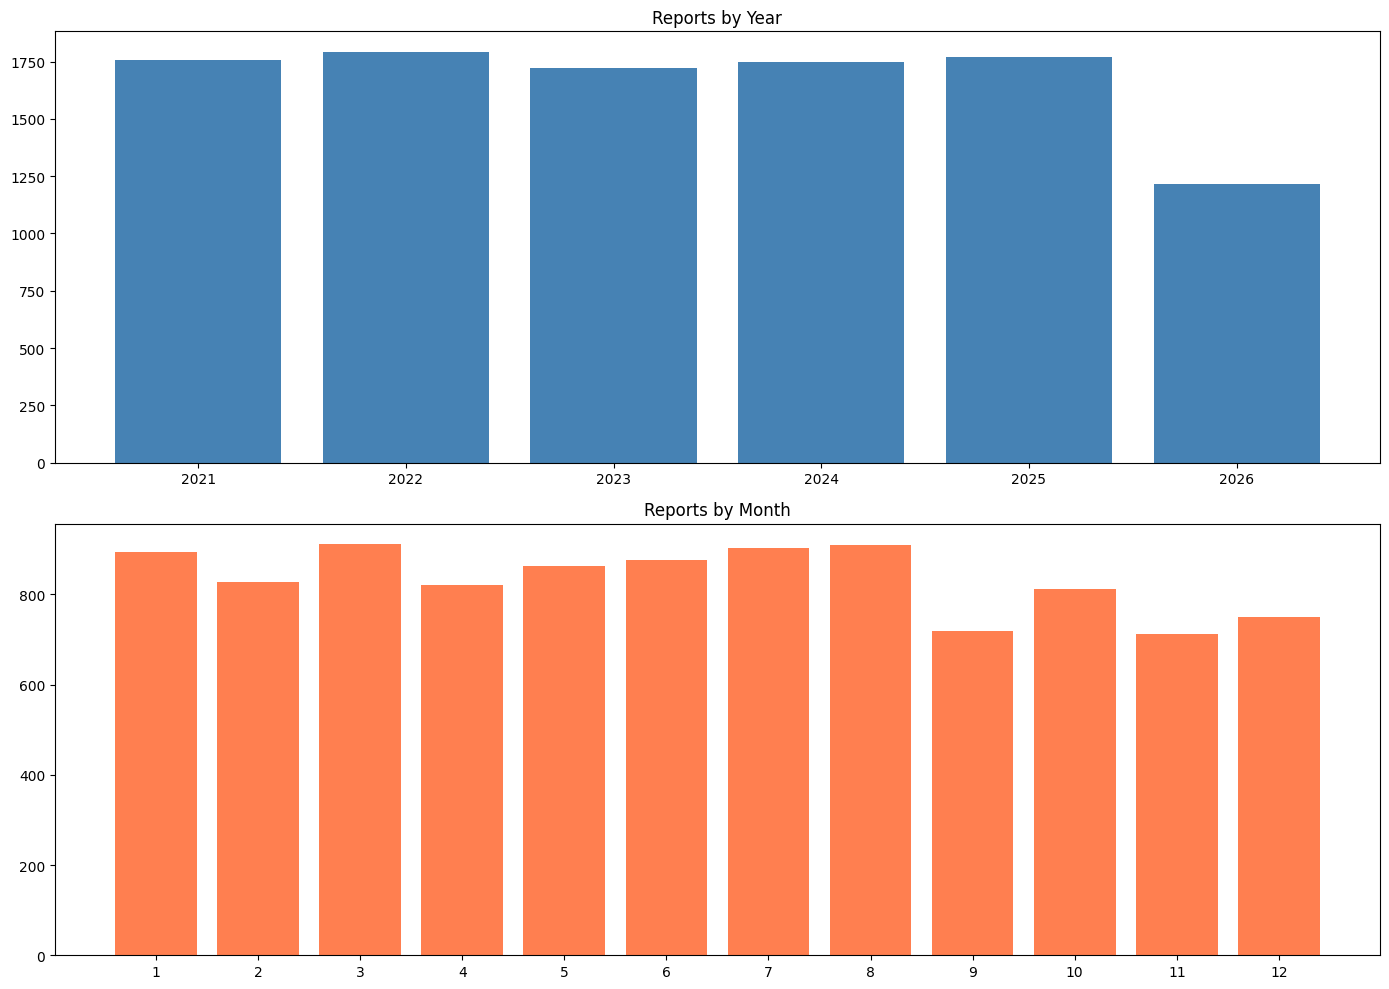

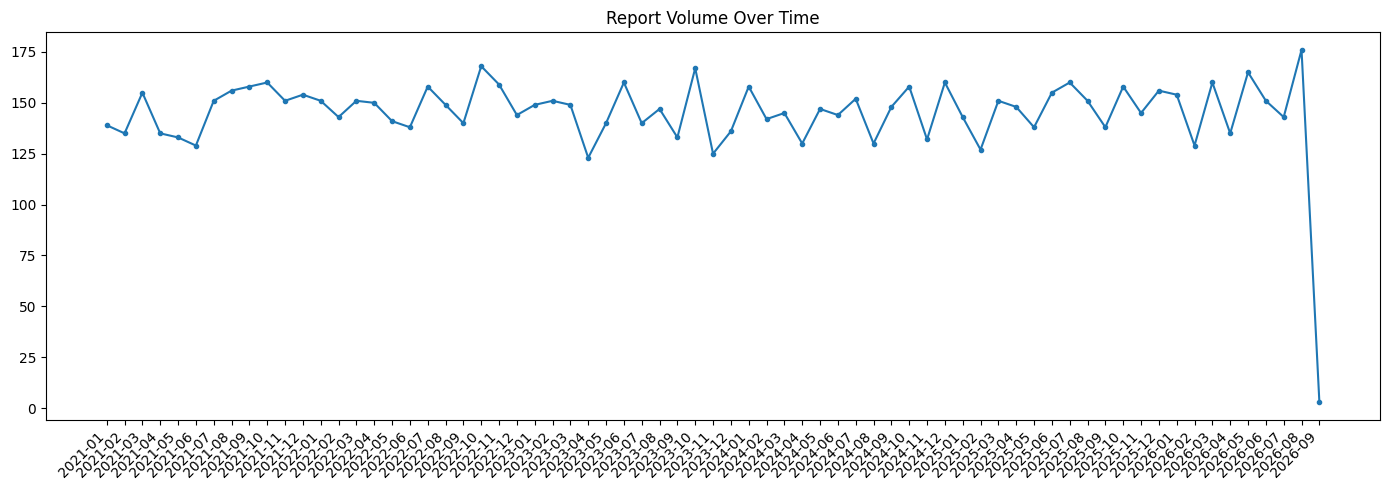

In [37]:
if DATE_COL is not None:
    df["parsed_date"] = pd.to_datetime(df[DATE_COL], errors="coerce")
    vd = df.dropna(subset=["parsed_date"]).copy()
    if len(vd):
        vd["year"]  = vd["parsed_date"].dt.year
        vd["month"] = vd["parsed_date"].dt.month
        vd["ym"]    = vd["parsed_date"].dt.to_period('M')
        fig, axes = plt.subplots(2, 1, figsize=(14, 10))
        yc = vd["year"].value_counts().sort_index()
        axes[0].bar(yc.index.astype(str), yc.values, color='steelblue')
        axes[0].set_title("Reports by Year")
        mc = vd["month"].value_counts().sort_index()
        axes[1].bar(mc.index, mc.values, color='coral')
        axes[1].set_title("Reports by Month")
        axes[1].set_xticks(range(1, 13))
        plt.tight_layout(); plt.show()
        series = vd.groupby("ym").size()
        plt.figure(figsize=(14, 5))
        plt.plot(series.index.astype(str), series.values, marker='o', ms=3)
        plt.xticks(rotation=45, ha='right')
        plt.title("Report Volume Over Time")
        plt.tight_layout(); plt.show()
    else:
        print("No valid dates.")
else:
    print("No date column.")

### 7.5 Threat actor

,Report Count
threat_actor,
SilverSpider,1295
ShadowFox,1287
APT-Alpha,1275
BlackOrchid,1274
NightWolf,1260
RedFalcon,1239
DarkHydra,1186
StormByte,1184


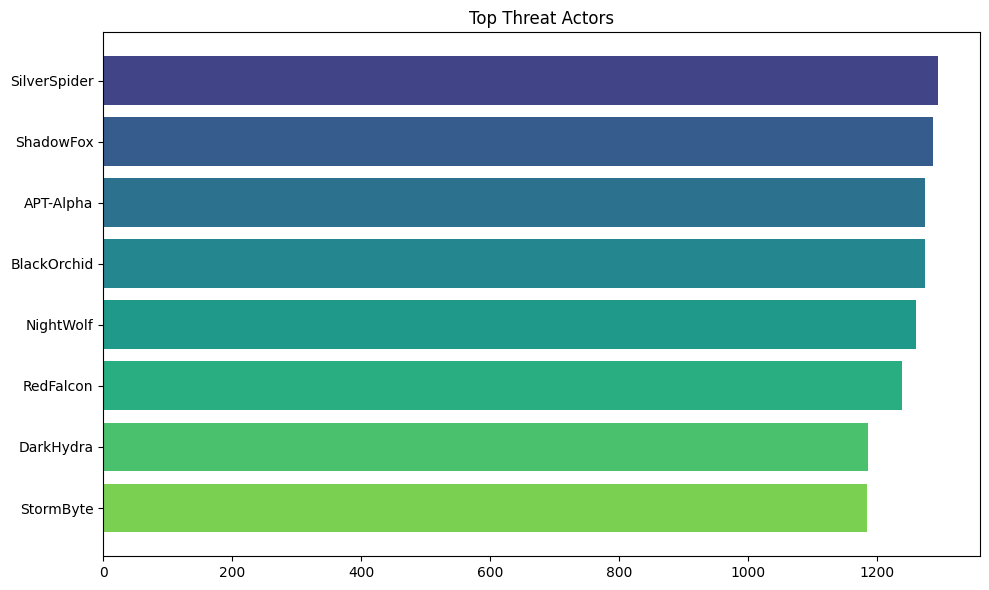

In [38]:
ACTOR_COL = find_column(df.columns,
    ["threat_actor", "actor", "attacker", "group"])
if ACTOR_COL is not None:
    ac = df[ACTOR_COL].value_counts()
    display(ac.head(15).to_frame("Report Count"))
    top = ac.head(15)
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(range(len(top)), top.values,
            color=plt.cm.viridis(np.linspace(0.2, 0.8, len(top))))
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(top.index)
    ax.invert_yaxis()
    ax.set_title("Top Threat Actors")
    plt.tight_layout(); plt.show()
else:
    print("No threat_actor column.")

### 7.6 Malware family

,Count
malware,
NightStealer,1284
DarkLoader,1260
BlackRAT,1254
ShadowRAT,1249
GhostLoader,1247
StormCrypt,1243
SilverWorm,1237
RedLineX,1226


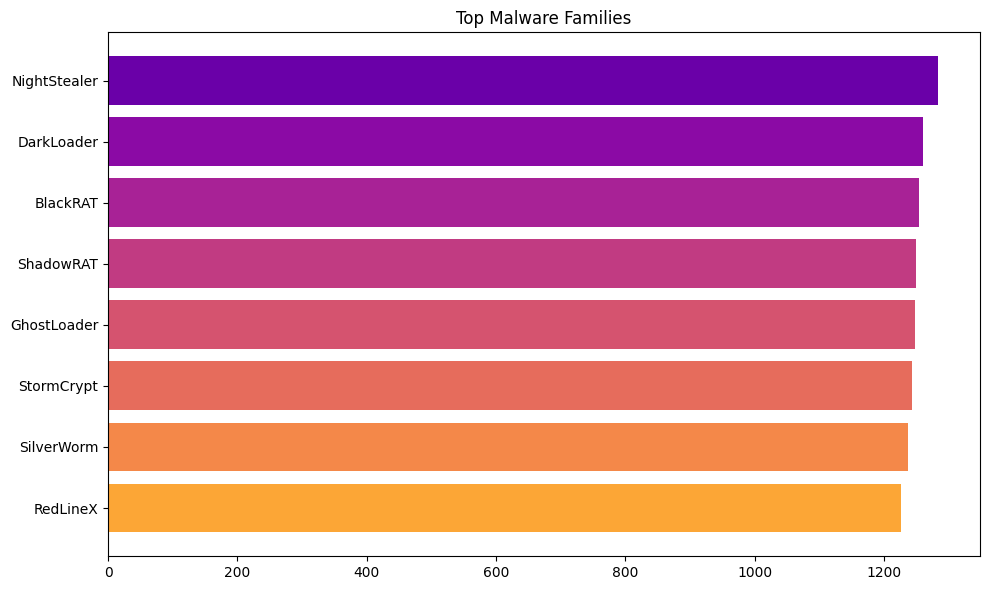

In [39]:
MALWARE_COL = find_column(df.columns,
    ["malware", "malware_family", "tool", "payload"])
if MALWARE_COL is not None:
    mc = df[MALWARE_COL].value_counts()
    display(mc.to_frame("Count"))
    top = mc.head(12)
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(range(len(top)), top.values,
            color=plt.cm.plasma(np.linspace(0.2, 0.8, len(top))))
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(top.index)
    ax.invert_yaxis()
    ax.set_title("Top Malware Families")
    plt.tight_layout(); plt.show()
else:
    print("No malware column.")

### 7.7 Attack vector

,Count
attack_vector,
Drive-by Download,1048
Malicious Attachment,1032
Compromised Website,1019
Malicious Link,1005
Spear Phishing,995
Brute Force,990
Credential Stuffing,984
Supply Chain,983
Remote Desktop,981


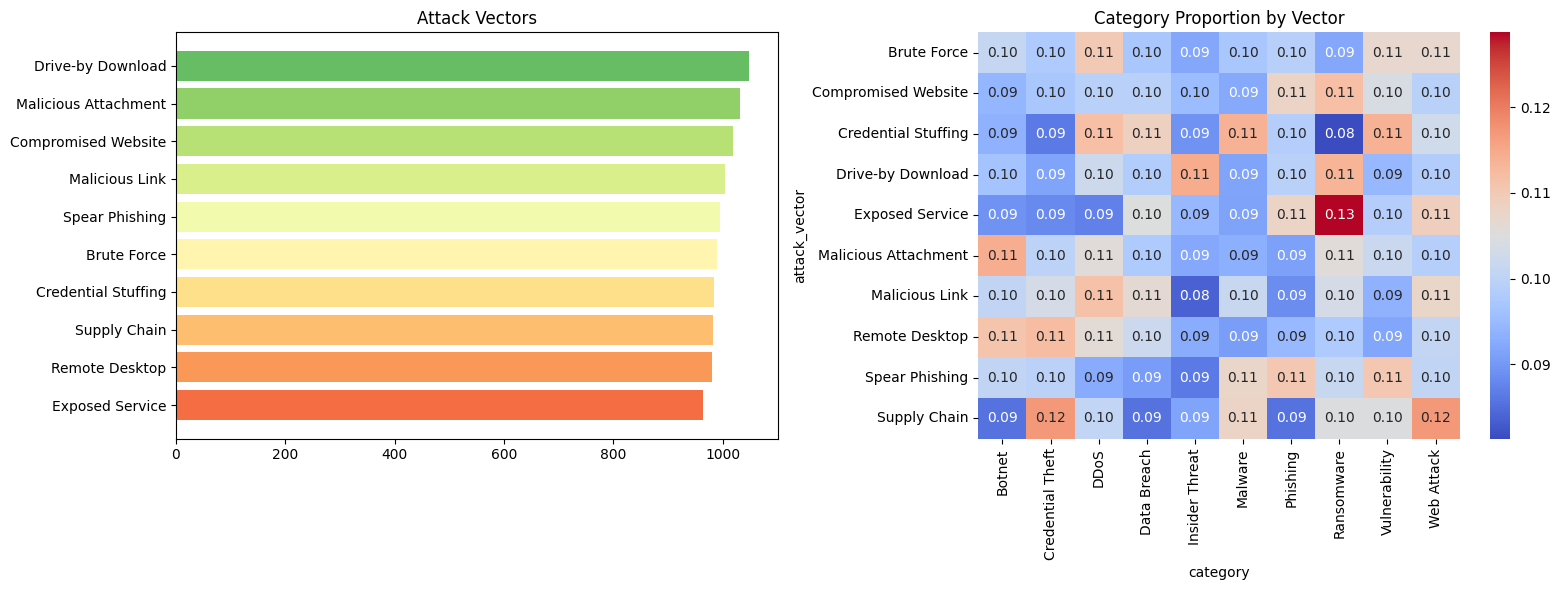

In [40]:
VECTOR_COL = find_column(df.columns,
    ["attack_vector", "vector", "attack_method", "initial_access"])
if VECTOR_COL is not None:
    vc = df[VECTOR_COL].value_counts()
    display(vc.to_frame("Count"))
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    axes[0].barh(vc.index, vc.values,
                 color=plt.cm.RdYlGn_r(np.linspace(0.2, 0.8, len(vc))))
    axes[0].invert_yaxis()
    axes[0].set_title("Attack Vectors")
    vcat = pd.crosstab(df[VECTOR_COL], df[LABEL_COL],
                       normalize='index')
    sns.heatmap(vcat, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1])
    axes[1].set_title("Category Proportion by Vector")
    plt.tight_layout(); plt.show()
else:
    print("No attack_vector column.")

### 7.8 Geography

,Count
country,
United States,1053
France,1032
Germany,1015
Brazil,1014
Japan,1010
Singapore,996
United Kingdom,994
Canada,988
Australia,982


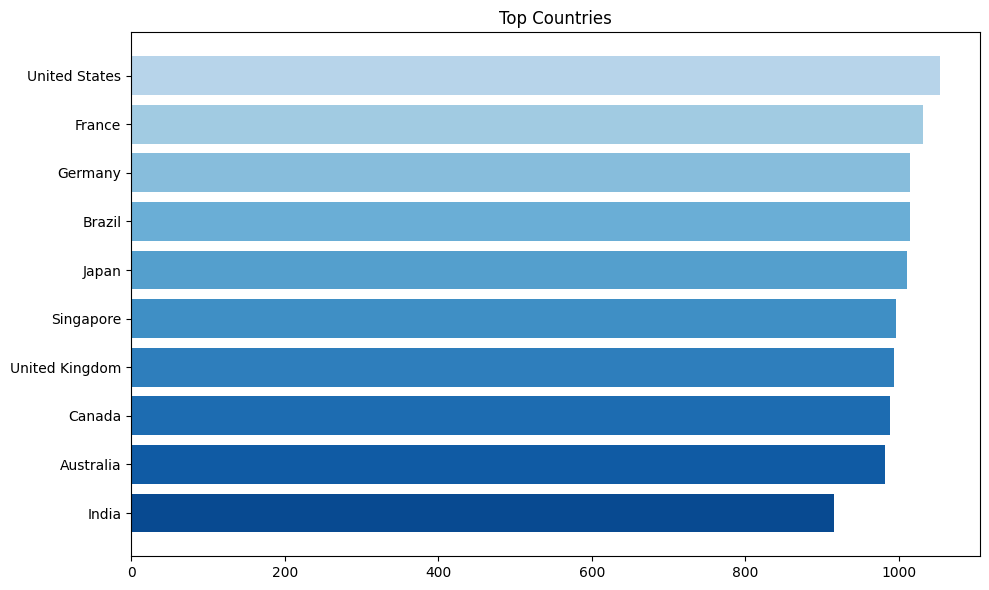

In [41]:
COUNTRY_COL = find_column(df.columns,
    ["country", "nation", "region", "location"])
if COUNTRY_COL is not None:
    cc = df[COUNTRY_COL].value_counts()
    display(cc.head(15).to_frame("Count"))
    top = cc.head(15)
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(range(len(top)), top.values,
            color=plt.cm.Blues(np.linspace(0.3, 0.9, len(top))))
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(top.index)
    ax.invert_yaxis()
    ax.set_title("Top Countries")
    plt.tight_layout(); plt.show()
else:
    print("No country column.")

### 7.9 MITRE ATT&CK techniques

,Count
mitre_technique,
T1003,701
T1498,698
T1053,694
T1547.001,678
T1566.002,676
T1059.001,669
T1021.001,661
T1566,660
T1486,660


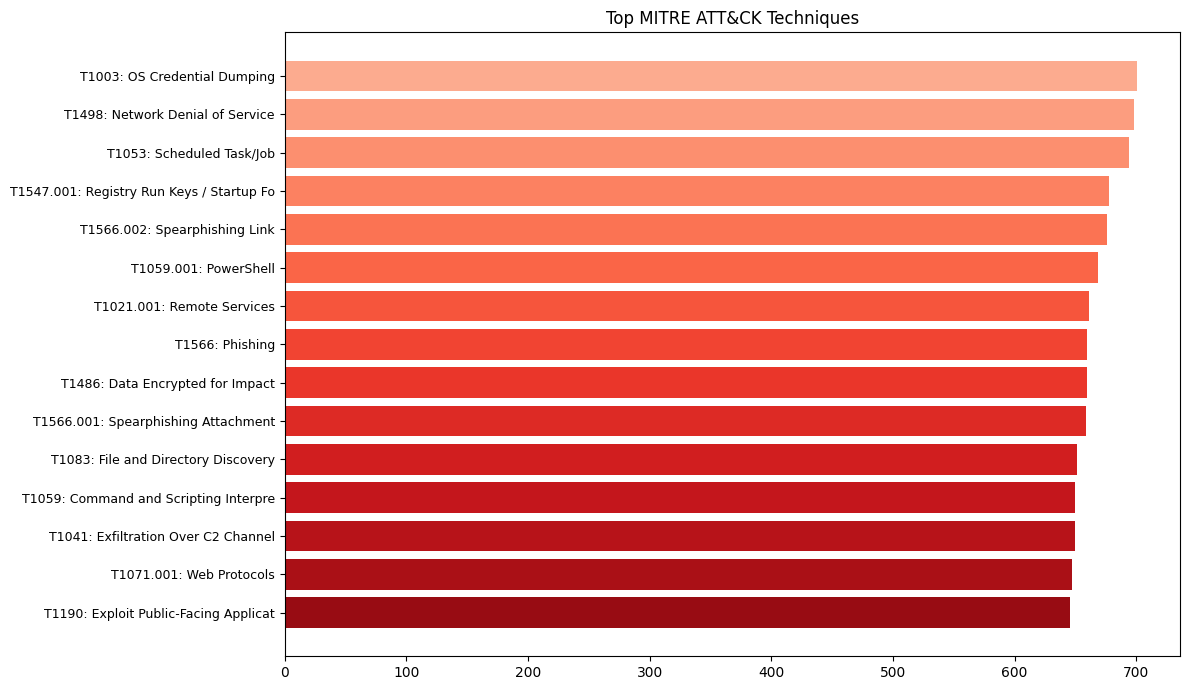

In [42]:
MITRE_COL = find_column(df.columns,
    ["mitre_technique", "technique", "attack_technique", "mitre_id"])
MITRE_NAME_COL = find_column(df.columns,
    ["mitre_technique_name", "technique_name", "mitre_name"])
if MITRE_COL is not None:
    tc = df[MITRE_COL].value_counts()
    display(tc.head(15).to_frame("Count"))
    top = tc.head(15)
    if MITRE_NAME_COL is not None:
        names = df.groupby(MITRE_COL)[MITRE_NAME_COL].first()
        labels = [f"{t}: {str(names.get(t, ''))[:30]}"
                  for t in top.index]
    else:
        labels = list(top.index)
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.barh(range(len(top)), top.values,
            color=plt.cm.Reds(np.linspace(0.3, 0.9, len(top))))
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(labels, fontsize=9)
    ax.invert_yaxis()
    ax.set_title("Top MITRE ATT&CK Techniques")
    plt.tight_layout(); plt.show()
else:
    print("No MITRE technique column.")

### 7.10 Cramér's V — categorical associations

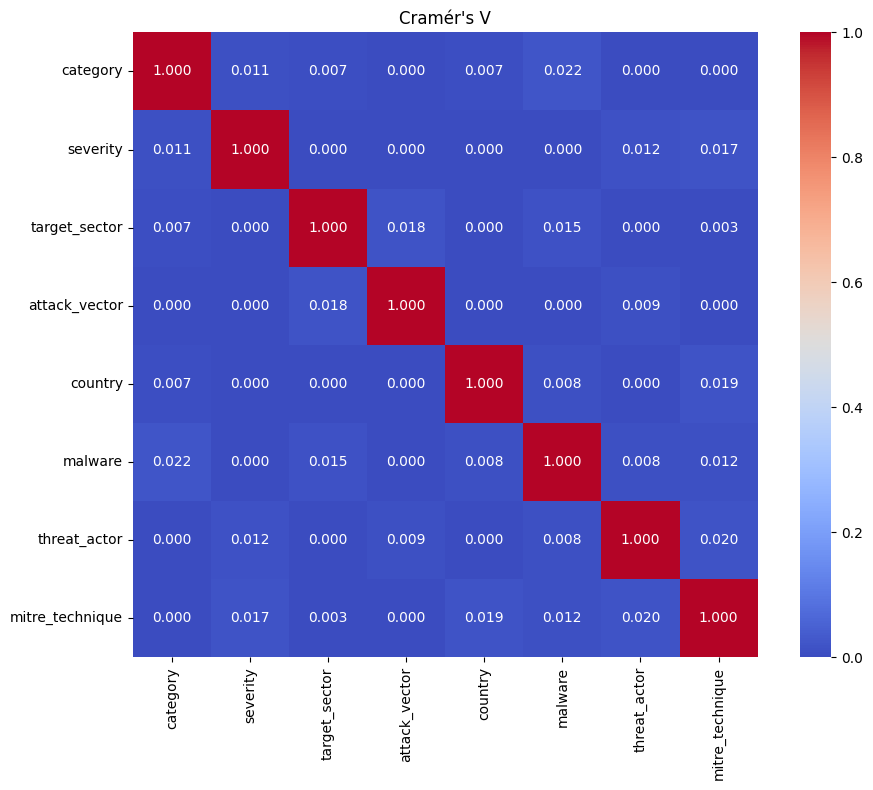

In [43]:
from scipy.stats import chi2_contingency
def cramers_v(x, y):
    cm = pd.crosstab(x, y)
    chi2 = chi2_contingency(cm)[0]
    n = cm.sum().sum()
    phi2 = chi2 / n
    r, k = cm.shape
    phi2c = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rc = r - ((r-1)**2)/(n-1)
    kc = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2c / max(min(kc, rc) - 1, 1))

feats = [LABEL_COL]
for name in ["severity", "target_sector", "attack_vector",
             "country", "malware", "threat_actor",
             "mitre_technique"]:
    col = find_column(df.columns, [name])
    if col is not None and col not in feats:
        feats.append(col)

if len(feats) >= 2:
    n = len(feats)
    M = pd.DataFrame(np.zeros((n, n)), index=feats, columns=feats)
    for i in range(n):
        for j in range(n):
            if i == j:
                M.iloc[i, j] = 1.0
            elif i < j:
                try:
                    v = cramers_v(df[feats[i]], df[feats[j]])
                except Exception:
                    v = 0
                M.iloc[i, j] = M.iloc[j, i] = v
    plt.figure(figsize=(10, 8))
    sns.heatmap(M, annot=True, fmt='.3f', cmap='coolwarm',
                vmin=0, vmax=1, square=True)
    plt.title("Cramér's V")
    plt.tight_layout(); plt.show()

### 7.11 Text length / word count by category

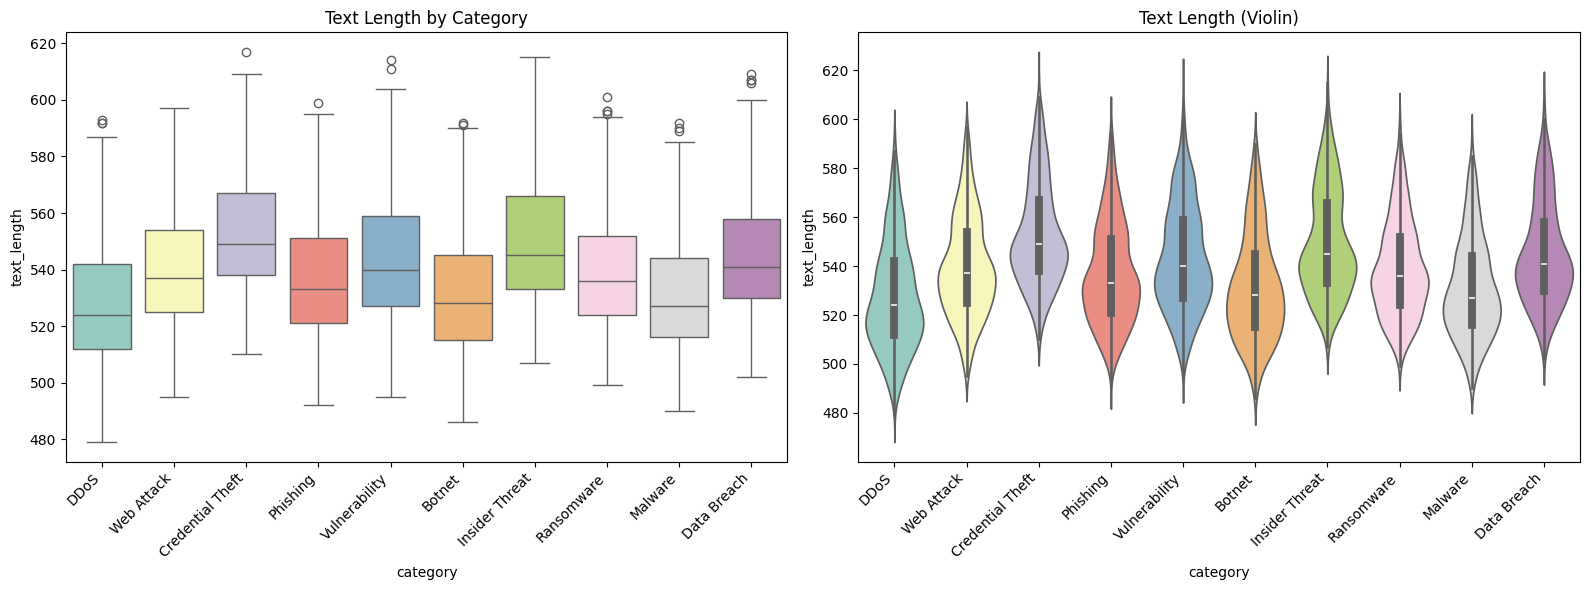

,mean,median,min,max
category,,,,
Botnet,64.5,64.0,60,75
Credential Theft,66.6,66.0,62,77
DDoS,64.8,64.0,60,75
Data Breach,66.9,66.0,63,77
Insider Threat,66.8,66.0,62,75
Malware,64.2,63.0,60,74
Phishing,64.6,64.0,60,74
Ransomware,64.4,64.0,60,74
Vulnerability,64.3,63.0,60,76


In [44]:
if "text_length" not in df.columns:
    df["text_length"] = df["model_text"].str.len()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=df, x=LABEL_COL, y="text_length", ax=axes[0],
            palette="Set3")
axes[0].set_xticklabels(axes[0].get_xticklabels(),
                        rotation=45, ha='right')
axes[0].set_title("Text Length by Category")
sns.violinplot(data=df, x=LABEL_COL, y="text_length", ax=axes[1],
               palette="Set3")
axes[1].set_xticklabels(axes[1].get_xticklabels(),
                        rotation=45, ha='right')
axes[1].set_title("Text Length (Violin)")
plt.tight_layout(); plt.show()
df["word_count"] = df["model_text"].str.split().str.len()
display(df.groupby(LABEL_COL)["word_count"]
        .agg(["mean", "median", "min", "max"]).round(1))

### 7.12 Key EDA findings

• 10 balanced threat categories (~10% each)
• Severity, sector, actor, malware, vector, country, MITRE all show category-specific skew
• Temporal volume is non-uniform → strong signal for NMF topic-drift detection
• Cramér's V quantifies which categorical fields are most predictive
• Text/word length varies by category → informs vectorizer parameters

## 8. Train / test split

In [45]:
X = df["model_text"]
y = df[LABEL_COL]
cc = y.value_counts()
strat = y.nunique() > 1 and cc.min() >= 2
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE,
    stratify=y if strat else None)
print("Train:", len(X_train), "| Test:", len(X_test),
      "| Classes:", y_train.nunique())

Train: 8000 | Test: 2000 | Classes: 10


## 9. Train baseline classifiers

In [46]:
models = {
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(max_features=10000,
                                  ngram_range=(1, 2),
                                  stop_words="english",
                                  sublinear_tf=True)),
        ("clf", LogisticRegression(max_iter=2000,
                                   class_weight="balanced",
                                   random_state=RANDOM_STATE)),
    ]),
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(max_features=10000,
                                  ngram_range=(1, 2),
                                  stop_words="english")),
        ("clf", MultinomialNB()),
    ]),
    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(max_features=10000,
                                  ngram_range=(1, 2),
                                  stop_words="english",
                                  sublinear_tf=True)),
        ("clf", LinearSVC(class_weight="balanced",
                          random_state=RANDOM_STATE)),
    ]),
}

results = []
trained = {}
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    p, r, f, _ = precision_recall_fscore_support(
        y_test, preds, average="weighted", zero_division=0)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Weighted Precision": p,
        "Weighted Recall": r,
        "Weighted F1": f,
    })
    trained[name] = model

results_df = (pd.DataFrame(results)
              .sort_values("Weighted F1", ascending=False)
              .reset_index(drop=True))
display(results_df.round(4))

Training Logistic Regression...
Training Multinomial Naive Bayes...
Training Linear SVM...


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1
0,Logistic Regression,1.0,1.0,1.0,1.0
1,Multinomial Naive Bayes,1.0,1.0,1.0,1.0
2,Linear SVM,1.0,1.0,1.0,1.0


## 10. Classification report + confusion matrix

Best baseline: Logistic Regression
                  precision    recall  f1-score   support

          Botnet       1.00      1.00      1.00       197
Credential Theft       1.00      1.00      1.00       199
            DDoS       1.00      1.00      1.00       205
     Data Breach       1.00      1.00      1.00       198
  Insider Threat       1.00      1.00      1.00       187
         Malware       1.00      1.00      1.00       197
        Phishing       1.00      1.00      1.00       197
      Ransomware       1.00      1.00      1.00       208
   Vulnerability       1.00      1.00      1.00       204
      Web Attack       1.00      1.00      1.00       208

        accuracy                           1.00      2000
       macro avg       1.00      1.00      1.00      2000
    weighted avg       1.00      1.00      1.00      2000



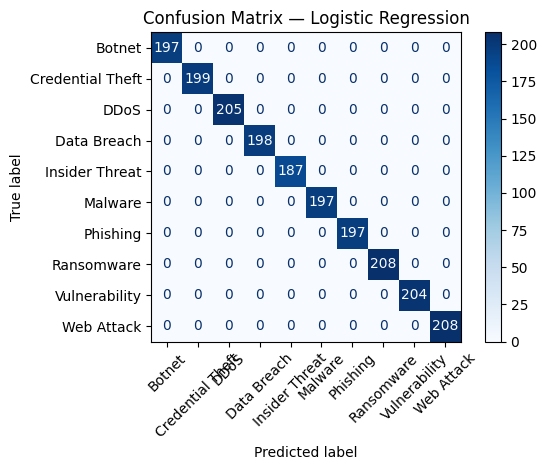

In [47]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained[best_model_name]
y_pred = best_model.predict(X_test)
print("Best baseline:", best_model_name)
print(classification_report(y_test, y_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, xticks_rotation=45, cmap="Blues")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout(); plt.show()

## 11. Classify extracted documents

Every document loaded in Section 2 is scored by the trained classifier. 
Results are shown as predicted category + confidence (when available).

In [48]:
if not uploaded_df.empty and (uploaded_df["text"] != "").any():
    docs = uploaded_df[uploaded_df["text"] != ""].copy()
    docs["predicted_category"] = best_model.predict(docs["text"])

    # Confidence / decision score if the underlying estimator supports it
    clf = best_model.named_steps["clf"]
    if hasattr(clf, "predict_proba"):
        probs = best_model.predict_proba(docs["text"])
        docs["confidence"] = probs.max(axis=1).round(4)
    elif hasattr(clf, "decision_function"):
        scores = best_model.decision_function(docs["text"])
        docs["confidence"] = np.max(scores, axis=1).round(4)
    else:
        docs["confidence"] = np.nan

    display(docs[[
        "file_name", "extension", "word_count",
        "predicted_category", "confidence"
    ]].sort_values("confidence", ascending=False))

    plt.figure(figsize=(10, 5))
    docs["predicted_category"].value_counts().plot(kind="bar",
                                                   color="steelblue")
    plt.title("Predicted Categories for Extracted Documents")
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout(); plt.show()
else:
    print("No extracted documents available to classify.")
    print("Add files to:", UPLOAD_DIR, "and re-run Section 2.")

No extracted documents available to classify.
Add files to: D:\Sachin Chakrawarti\Learn\done\thesis\ctc_ectd\uploads and re-run Section 2.


## 12. Combine training corpus + extracted docs for temporal analysis

Extracted documents without a date are treated as "latest month" so they 
influence the emerging-trend detection only if a date can be parsed from 
the filename or their text. Otherwise they are excluded from trend math.

In [49]:
# Parse a date from filename like 2024-08_report.pdf, or from text
DATE_RE = re.compile(r"(20\d{2})[-_/](\d{1,2})")

def guess_date(row):
    m = DATE_RE.search(row["file_name"])
    if m:
        return pd.Timestamp(year=int(m.group(1)), month=int(m.group(2)), day=1)
    # try first 500 chars of text
    m = DATE_RE.search(row["text"][:500])
    if m:
        return pd.Timestamp(year=int(m.group(1)), month=int(m.group(2)), day=1)
    return pd.NaT

if not uploaded_df.empty:
    docs = uploaded_df[uploaded_df["text"] != ""].copy()
    docs["parsed_date"] = docs.apply(guess_date, axis=1)
    docs["model_text"] = docs["text"]
    docs["source"] = "uploaded"
else:
    docs = pd.DataFrame(columns=["file_name", "text", "model_text",
                                 "parsed_date", "source"])

df["parsed_date"] = (pd.to_datetime(df[DATE_COL], errors="coerce")
                     if DATE_COL else pd.NaT)
df["source"] = "training"

temporal_df = pd.concat(
    [df[["model_text", "parsed_date", "source", LABEL_COL]],
     docs.reindex(columns=["model_text", "parsed_date", "source", LABEL_COL])],
    ignore_index=True,
).dropna(subset=["parsed_date"]).copy()

temporal_df["month"] = (temporal_df["parsed_date"]
                        .dt.to_period("M").astype(str))

print("Temporal corpus size:", len(temporal_df))
print("Months covered:", temporal_df["month"].nunique())
print("Sources:", temporal_df["source"].value_counts().to_dict())

Temporal corpus size: 10000
Months covered: 69
Sources: {'training': 10000}


## 13. Temporal topic modeling with NMF

Topic 1: activity, followed malicious, gain, followed, incident affecting, activity mapped, actor, activity involving, affecting, incident
Topic 2: activity, campaign, access linked, initial access, sector initial, additional activity, linked, affected systems, affected, campaign involved
Topic 3: behavior involving, activity corresponds, corresponds mitre, corresponds, threat intelligence, detected, monitoring, intelligence, intelligence monitoring, investigation activity
Topic 4: activity, located, investigation reported, targeted organizations, technique, reported mitre, reported, security analysts, activity identified, campaign targeted
Topic 5: web, attack, web attack, attack activity, identified web, attack behavior, detected web, involved web, attack incident, attack campaign


dominant_topic,1,2,3,4,5
month,,,,,
2021-01,0.237,0.216,0.230,0.223,0.094
2021-02,0.230,0.267,0.193,0.193,0.119
2021-03,0.181,0.239,0.219,0.271,0.090
2021-04,0.185,0.178,0.244,0.289,0.104
2021-05,0.218,0.211,0.256,0.241,0.075
...,...,...,...,...,...
2026-05,0.218,0.255,0.242,0.218,0.067
2026-06,0.205,0.225,0.205,0.272,0.093
2026-07,0.245,0.238,0.133,0.210,0.175


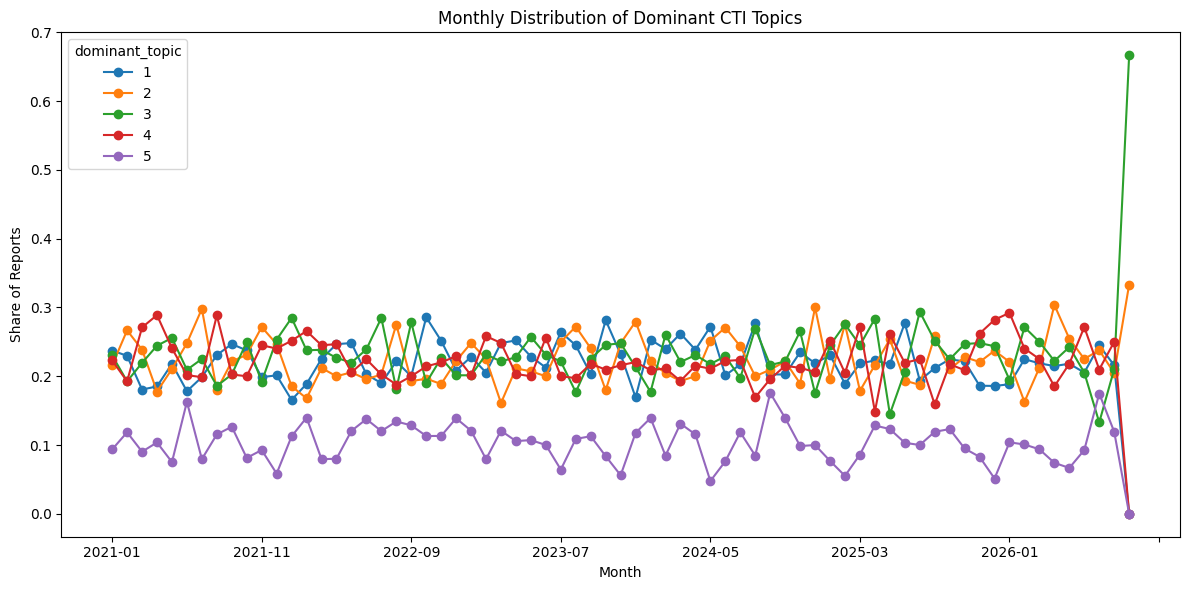

In [50]:
if len(temporal_df) >= 5:
    vec = TfidfVectorizer(max_features=5000, stop_words="english",
                          ngram_range=(1, 2))
    M = vec.fit_transform(temporal_df["model_text"])
    k = min(5, M.shape[0], M.shape[1])
    if k >= 2:
        nmf = NMF(n_components=k, random_state=RANDOM_STATE,
                  init="nndsvda", max_iter=500)
        W = nmf.fit_transform(M)
        terms = vec.get_feature_names_out()
        for i, comp in enumerate(nmf.components_):
            top = comp.argsort()[-10:][::-1]
            print(f"Topic {i+1}:", ", ".join(terms[j] for j in top))

        for i in range(k):
            temporal_df[f"Topic_{i+1}"] = W[:, i]
        temporal_df["dominant_topic"] = W.argmax(axis=1) + 1

        monthly_topic_counts = pd.crosstab(
            temporal_df["month"], temporal_df["dominant_topic"])
        monthly_topic_shares = monthly_topic_counts.div(
            monthly_topic_counts.sum(axis=1), axis=0).fillna(0)

        display(monthly_topic_shares.round(3))
        monthly_topic_shares.plot(figsize=(12, 6), marker="o")
        plt.title("Monthly Distribution of Dominant CTI Topics")
        plt.xlabel("Month"); plt.ylabel("Share of Reports")
        plt.tight_layout(); plt.show()
    else:
        print("Not enough terms to fit multiple topics.")
else:
    print("Insufficient dated reports for temporal topic modeling.")

## 14. Emerging-threat detection

A topic is flagged as an **emerging pattern** when its month-over-month share 
rises by at least a threshold (default 10 pp) while the absolute report count 
in the current month is at least 2. Alerts are heuristic — they need analyst review.

In [51]:
EMERGING_MIN_SHARE_JUMP = 0.10   # 10 percentage points
EMERGING_MIN_COUNT      = 2

alerts = []
if "monthly_topic_shares" in globals():
    months = list(monthly_topic_shares.index)
    for i in range(1, len(months)):
        prev_m, curr_m = months[i-1], months[i]
        for tid in monthly_topic_shares.columns:
            ps = monthly_topic_shares.loc[prev_m, tid]
            cs = monthly_topic_shares.loc[curr_m, tid]
            cnt = monthly_topic_counts.loc[curr_m, tid]
            if (cs - ps) >= EMERGING_MIN_SHARE_JUMP and cnt >= EMERGING_MIN_COUNT:
                alerts.append({
                    "Previous Month": prev_m,
                    "Current Month": curr_m,
                    "Topic": tid,
                    "Previous Share": round(ps, 3),
                    "Current Share": round(cs, 3),
                    "Increase (pp)": round(cs - ps, 3),
                    "Current Report Count": cnt,
                })

alerts_df = pd.DataFrame(alerts)
if not alerts_df.empty:
    alerts_df = alerts_df.sort_values("Increase (pp)", ascending=False)
    display(alerts_df)
    alerts_df.to_csv(PROJECT_ROOT / "artifacts" / "emerging_threat_alerts.csv",
                     index=False)
    print("\nSaved alerts to artifacts/emerging_threat_alerts.csv")
else:
    print("No topic passed the emerging-threat threshold.")
    print("This does not prove absence of emerging threats.")

,Previous Month,Current Month,Topic,Previous Share,Current Share,Increase (pp),Current Report Count
2,2026-08,2026-09,3,0.210,0.667,0.456,2
1,2025-04,2025-05,4,0.149,0.261,0.112,36
0,2024-11,2024-12,2,0.189,0.300,0.111,48



Saved alerts to artifacts/emerging_threat_alerts.csv


## 15. Ad-hoc prediction on a new CTI snippet

In [52]:
new_report = """
Multiple organizations report suspicious credential theft activity.
Attackers use phishing emails to obtain account credentials
and attempt unauthorized access to corporate systems.
"""
predicted_category = best_model.predict([new_report])[0]
print("Predicted category:", predicted_category)

Predicted category: Credential Theft


## 16. Save the trained classifier + vectorizer

In [53]:
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
ARTIFACT_DIR.mkdir(exist_ok=True)
joblib.dump(best_model,
            ARTIFACT_DIR / "cti_text_classifier.joblib")
print("Saved:", ARTIFACT_DIR / "cti_text_classifier.joblib")
print("Selected model:", best_model_name)

Saved: D:\Sachin Chakrawarti\Learn\done\thesis\ctc_ectd\artifacts\cti_text_classifier.joblib
Selected model: Logistic Regression


## 17. Final summary

In [54]:
print("=" * 60)
print("CTI THREAT ANALYSIS — SUMMARY")
print("=" * 60)
print("Training corpus:",  len(df))
print("Threat categories:", df[LABEL_COL].nunique())
print("Uploaded docs:",    len(uploaded_df))
print("Best baseline:",    best_model_name)
display(results_df.round(4))
print("\nLimitations:")
print("1. Synthetic training data may not reflect real CTI.")
print("2. Extracted PDF text may be noisy — review before relying on it.")
print("3. Emerging alerts are heuristic signals, not confirmed threats.")
print("4. NMF topics require analyst interpretation.")

CTI THREAT ANALYSIS — SUMMARY
Training corpus: 10000
Threat categories: 10
Uploaded docs: 0
Best baseline: Logistic Regression


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1
0,Logistic Regression,1.0,1.0,1.0,1.0
1,Multinomial Naive Bayes,1.0,1.0,1.0,1.0
2,Linear SVM,1.0,1.0,1.0,1.0



Limitations:
1. Synthetic training data may not reflect real CTI.
2. Extracted PDF text may be noisy — review before relying on it.
3. Emerging alerts are heuristic signals, not confirmed threats.
4. NMF topics require analyst interpretation.
